# TechCamp CIS — Plant Anomaly Detection (FIXED)

**Pipeline:** PlantVillage → NORMAL/ANOMALY → stratified train/validation/test split → MobileNetV2 transfer learning → threshold selection on validation → final test evaluation → TFLite export → Raspberry Pi.

## Important fixes compared with the previous notebook

1. **No `validation_split` + batch slicing.** The previous notebook created a holdout dataset with `shuffle=False` and then used `.take()` / `.skip()` on batches. Because images were class-ordered, the test set could contain only NORMAL images. That is the direct cause of `AUC = nan`.
2. **Real image-level train/validation/test split.** Each class is split separately, so all three sets contain both classes.
3. **Explicit label order:** `0 = NORMAL`, `1 = ANOMALY`. This removes the confusing alphabetical-label problem.
4. **Correct probability interpretation:** the sigmoid output is the probability of ANOMALY.
5. **Threshold is selected using validation data only.** The test set remains untouched until final evaluation.
6. **AUC is protected against one-class failures.**
7. **One final evaluation section only.** No duplicated/conflicting evaluation code.
8. **Class distributions are printed before training and before final evaluation.**
9. **The TFLite `config.json` uses the same label mapping and threshold as the notebook.**


## 0. Google Drive strategy

With limited Drive storage, keep the raw PlantVillage dataset in temporary Colab storage.

Persistent files:

```text
My Drive/
└── TECHCAMP_CIS/
    ├── notebooks/
    ├── models/
    └── results/
```

The notebook saves the trained `.keras` model, `.tflite` model, labels, configuration, metrics, and training history to Drive.


In [1]:
# 1. Imports and environment

!pip -q install scikit-learn

import os
import json
import shutil
import random
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    f1_score,
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


TensorFlow: 2.20.0
GPU: []


## 1. Mount Google Drive

In [2]:
from google.colab import drive

drive.mount("/content/drive")

DRIVE_ROOT = "/content/drive/MyDrive/TECHCAMP_CIS"
MODEL_DIR = os.path.join(DRIVE_ROOT, "models")
RESULTS_DIR = os.path.join(DRIVE_ROOT, "results")
NOTEBOOK_DIR = os.path.join(DRIVE_ROOT, "notebooks")

for p in [MODEL_DIR, RESULTS_DIR, NOTEBOOK_DIR]:
    os.makedirs(p, exist_ok=True)

print("Drive project:", DRIVE_ROOT)


Mounted at /content/drive
Drive project: /content/drive/MyDrive/TECHCAMP_CIS


## 2. Download PlantVillage to temporary Colab storage

This uses the same public GitHub mirror as the previous notebook. The dataset is **not** copied to Drive.


In [3]:
%cd /content

DATA_ROOT = "/content/PlantVillage-Dataset"

if not os.path.exists(DATA_ROOT):
    !git clone --depth 1 https://github.com/gabrieldgf4/PlantVillage-Dataset.git

print("Dataset root:", DATA_ROOT)
!du -sh /content/PlantVillage-Dataset


/content
Cloning into 'PlantVillage-Dataset'...
remote: Enumerating objects: 54326, done.
remote: Counting objects: 100% (54326/54326), done.
remote: Compressing objects: 100% (54326/54326), done.
remote: Total 54326 (delta 0), reused 54285 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (54326/54326), 803.82 MiB | 27.94 MiB/s, done.
Updating files: 100% (54306/54306), done.
Dataset root: /content/PlantVillage-Dataset
1.7G	/content/PlantVillage-Dataset


## 3. Find original PlantVillage class folders

Folders containing image files are treated as original classes.

Mapping:
- original class name containing `healthy` → `NORMAL`
- all other classes → `ANOMALY`


In [4]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"}

class_dirs = []

for root, dirs, files in os.walk(DATA_ROOT):
    imgs = [f for f in files if Path(f).suffix in IMG_EXTS]
    if imgs:
        class_dirs.append((Path(root), imgs))

print("Image-containing class folders:", len(class_dirs))

for root, imgs in class_dirs[:50]:
    print(f"{root} -> {len(imgs)} images")


Image-containing class folders: 39
/content/PlantVillage-Dataset/Peach___healthy -> 360 images
/content/PlantVillage-Dataset/Pepper,_bell___healthy -> 1476 images
/content/PlantVillage-Dataset/x_Removed_from_Healthy_leaves -> 5 images
/content/PlantVillage-Dataset/Tomato___Tomato_Yellow_Leaf_Curl_Virus -> 5357 images
/content/PlantVillage-Dataset/Potato___Early_blight -> 1000 images
/content/PlantVillage-Dataset/Apple___Cedar_apple_rust -> 275 images
/content/PlantVillage-Dataset/Tomato___Target_Spot -> 1404 images
/content/PlantVillage-Dataset/Tomato___Tomato_mosaic_virus -> 373 images
/content/PlantVillage-Dataset/Tomato___Late_blight -> 1909 images
/content/PlantVillage-Dataset/Apple___Black_rot -> 621 images
/content/PlantVillage-Dataset/Apple___healthy -> 1645 images
/content/PlantVillage-Dataset/Raspberry___healthy -> 371 images
/content/PlantVillage-Dataset/Cherry_(including_sour)___Powdery_mildew -> 1052 images
/content/PlantVillage-Dataset/Soybean___healthy -> 5089 images
/con

## 4. Build binary NORMAL / ANOMALY source folders

The default keeps at most 300 images from each original PlantVillage class so the Colab prototype remains practical.

Set `MAX_IMAGES_PER_ORIGINAL_CLASS = None` if you want to use every available image.


In [5]:
MAX_IMAGES_PER_ORIGINAL_CLASS = 300

BINARY_ROOT = "/content/techcamp_binary_source"
NORMAL_DIR = os.path.join(BINARY_ROOT, "NORMAL")
ANOMALY_DIR = os.path.join(BINARY_ROOT, "ANOMALY")

if os.path.exists(BINARY_ROOT):
    shutil.rmtree(BINARY_ROOT)

os.makedirs(NORMAL_DIR)
os.makedirs(ANOMALY_DIR)

total_normal = 0
total_anomaly = 0

for class_dir, files in class_dirs:
    class_name = class_dir.name
    files = files.copy()
    random.Random(SEED).shuffle(files)

    if MAX_IMAGES_PER_ORIGINAL_CLASS is not None:
        files = files[:MAX_IMAGES_PER_ORIGINAL_CLASS]

    is_normal = "healthy" in class_name.lower()
    target = Path(NORMAL_DIR if is_normal else ANOMALY_DIR)

    for i, fname in enumerate(files):
        src = class_dir / fname
        dst = target / f"{class_name}__{i:05d}{src.suffix.lower()}"

        try:
            os.symlink(src, dst)
        except OSError:
            shutil.copy2(src, dst)

    if is_normal:
        total_normal += len(files)
    else:
        total_anomaly += len(files)

print("NORMAL:", total_normal)
print("ANOMALY:", total_anomaly)
print("TOTAL:", total_normal + total_anomaly)


NORMAL: 3457
ANOMALY: 7775
TOTAL: 11232


## 5. Robust image-level train / validation / test split

**This is the main fix.**

We do **not** create one ordered holdout dataset and then split it with `.take()` / `.skip()`.

Instead, each class is split independently:

- 70% train
- 15% validation
- 15% test

Therefore, validation and test are guaranteed to contain both NORMAL and ANOMALY images as long as each class has enough images.


In [6]:
SPLIT_ROOT = "/content/techcamp_binary_split"

if os.path.exists(SPLIT_ROOT):
    shutil.rmtree(SPLIT_ROOT)

for split in ["train", "val", "test"]:
    for class_name in ["NORMAL", "ANOMALY"]:
        os.makedirs(os.path.join(SPLIT_ROOT, split, class_name), exist_ok=True)


def split_class_files(source_dir, seed=42):
    files = [
        Path(source_dir) / f
        for f in os.listdir(source_dir)
        if Path(f).suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

    rng = random.Random(seed)
    rng.shuffle(files)

    n = len(files)

    n_train = int(0.70 * n)
    n_val = int(0.15 * n)

    train_files = files[:n_train]
    val_files = files[n_train:n_train + n_val]
    test_files = files[n_train + n_val:]

    return train_files, val_files, test_files


def link_or_copy(files, destination):
    for src in files:
        dst = Path(destination) / src.name

        try:
            os.symlink(src, dst)
        except OSError:
            shutil.copy2(src, dst)


for class_name in ["NORMAL", "ANOMALY"]:
    source = os.path.join(BINARY_ROOT, class_name)

    train_files, val_files, test_files = split_class_files(
        source,
        seed=SEED
    )

    link_or_copy(
        train_files,
        os.path.join(SPLIT_ROOT, "train", class_name)
    )

    link_or_copy(
        val_files,
        os.path.join(SPLIT_ROOT, "val", class_name)
    )

    link_or_copy(
        test_files,
        os.path.join(SPLIT_ROOT, "test", class_name)
    )

    print(
        class_name,
        "->",
        "train:", len(train_files),
        "val:", len(val_files),
        "test:", len(test_files)
    )


NORMAL -> train: 2419 val: 518 test: 520
ANOMALY -> train: 5442 val: 1166 test: 1167


## 6. Verify the split **before training**

In [7]:
def count_images(folder):
    counts = {}

    for class_name in ["NORMAL", "ANOMALY"]:
        class_dir = os.path.join(folder, class_name)

        counts[class_name] = sum(
            1
            for f in os.listdir(class_dir)
            if Path(f).suffix.lower() in {".jpg", ".jpeg", ".png"}
        )

    return counts


train_counts = count_images(os.path.join(SPLIT_ROOT, "train"))
val_counts = count_images(os.path.join(SPLIT_ROOT, "val"))
test_counts = count_images(os.path.join(SPLIT_ROOT, "test"))

print("TRAIN:", train_counts)
print("VALIDATION:", val_counts)
print("TEST:", test_counts)

assert train_counts["NORMAL"] > 0 and train_counts["ANOMALY"] > 0
assert val_counts["NORMAL"] > 0 and val_counts["ANOMALY"] > 0
assert test_counts["NORMAL"] > 0 and test_counts["ANOMALY"] > 0

print("\nSUCCESS: every split contains BOTH classes.")


TRAIN: {'NORMAL': 2419, 'ANOMALY': 5442}
VALIDATION: {'NORMAL': 518, 'ANOMALY': 1166}
TEST: {'NORMAL': 520, 'ANOMALY': 1167}

SUCCESS: every split contains BOTH classes.


## 7. Create TensorFlow datasets

We explicitly set:

```text
0 = NORMAL
1 = ANOMALY
```

The sigmoid output is therefore the **ANOMALY probability**.


In [8]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

CLASS_NAMES = ["NORMAL", "ANOMALY"]

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_ROOT, "train"),
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_ROOT, "val"),
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False,
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_ROOT, "test"),
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False,
)

print("Keras class names:", train_ds.class_names)
print("Mapping: 0 = NORMAL, 1 = ANOMALY")

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)


Found 7861 files belonging to 2 classes.
Found 1684 files belonging to 2 classes.
Found 1687 files belonging to 2 classes.
Keras class names: ['NORMAL', 'ANOMALY']
Mapping: 0 = NORMAL, 1 = ANOMALY


## 8. Visual sanity check

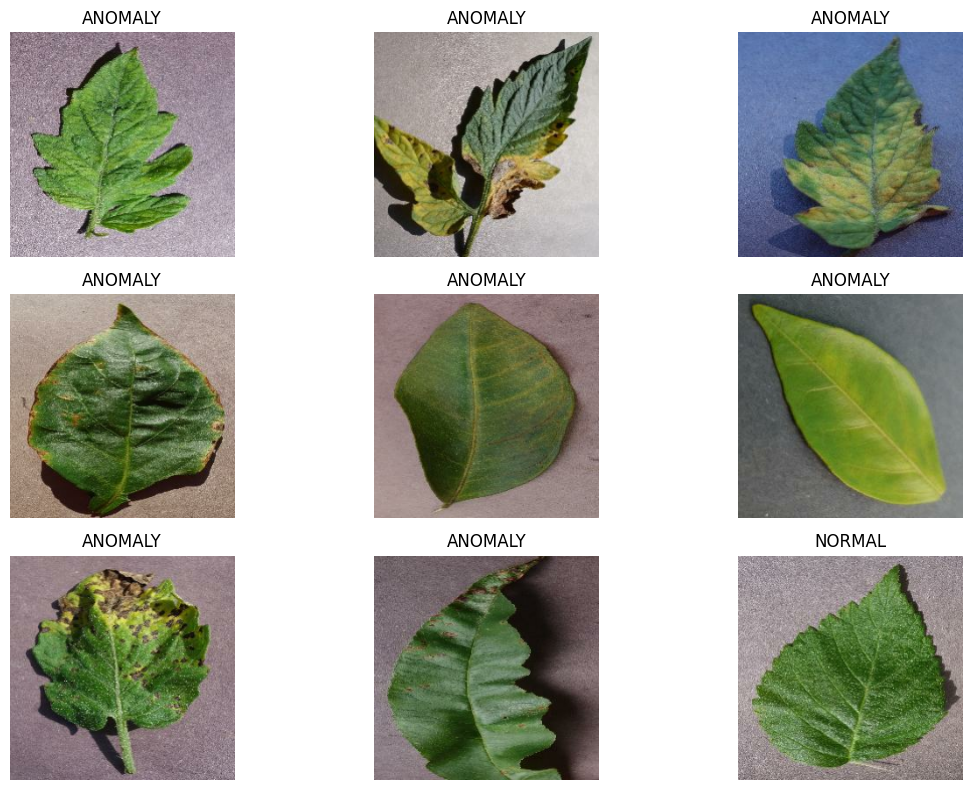

In [9]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label = int(labels[i].numpy()[0])
        plt.title(CLASS_NAMES[label])
        plt.axis("off")

plt.tight_layout()
plt.show()


## 9. MobileNetV2 transfer learning

The pretrained MobileNetV2 backbone is frozen first. A small binary classification head is trained on top.


In [10]:
base = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet"
)

base.trainable = False

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10),
], name="augmentation")

inputs = tf.keras.Input(shape=IMG_SIZE + (3,))

x = augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.25)(x)

# IMPORTANT:
# 0 = NORMAL
# 1 = ANOMALY
# sigmoid output = probability of ANOMALY
outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid",
    name="anomaly_probability"
)(x)

model = tf.keras.Model(
    inputs,
    outputs,
    name="TechCamp_MobileNetV2"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ],
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "TechCamp_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ anomaly_probability (Dense)     │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 10. Class weights

The PlantVillage binary dataset can be imbalanced because many original disease classes map to ANOMALY while fewer classes map to NORMAL.

Class weights reduce the tendency to ignore the minority class.


In [11]:
n_normal = train_counts["NORMAL"]
n_anomaly = train_counts["ANOMALY"]
n_total = n_normal + n_anomaly

class_weight = {
    0: n_total / (2.0 * n_normal),
    1: n_total / (2.0 * n_anomaly),
}

print("Class weights:", class_weight)


Class weights: {0: 1.624844977263332, 1: 0.7222528482175671}


## 11. Train and save the best model

In [12]:
BEST_MODEL = os.path.join(
    MODEL_DIR,
    "best_mobilenetv2_fixed.keras"
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        BEST_MODEL,
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1,
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=4,
        restore_best_weights=True,
        verbose=1,
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        verbose=1,
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weight,
    callbacks=callbacks,
)

print("Best model:", BEST_MODEL)


Epoch 1/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 0s 979ms/step - accuracy: 0.7656 - auc: 0.8539 - loss: 0.4539 - precision: 0.8788 - recall: 0.7555
Epoch 1: val_auc improved from None to 0.98072, saving model to /content/drive/MyDrive/TECHCAMP_CIS/models/best_mobilenetv2_fixed.keras

Epoch 1: finished saving model to /content/drive/MyDrive/TECHCAMP_CIS/models/best_mobilenetv2_fixed.keras
246/246 ━━━━━━━━━━━━━━━━━━━━ 290s 1s/step - accuracy: 0.8573 - auc: 0.9421 - loss: 0.3195 - precision: 0.9392 - recall: 0.8488 - val_accuracy: 0.9329 - val_auc: 0.9807 - val_loss: 0.1857 - val_precision: 0.9697 - val_recall: 0.9322 - learning_rate: 0.0010
Epoch 2/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 0s 994ms/step - accuracy: 0.9191 - auc: 0.9772 - loss: 0.2057 - precision: 0.9686 - recall: 0.9108
Epoch 2: val_auc improved from 0.98072 to 0.98679, saving model to /content/drive/MyDrive/TECHCAMP_CIS/models/best_mobilenetv2_fixed.keras

Epoch 2: finished saving model to /content/drive/MyDrive/TECHCAMP_CIS/models/best_m

## 12. Training curves

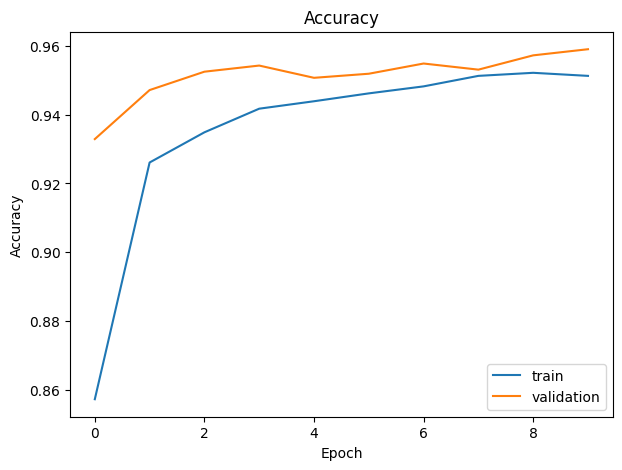

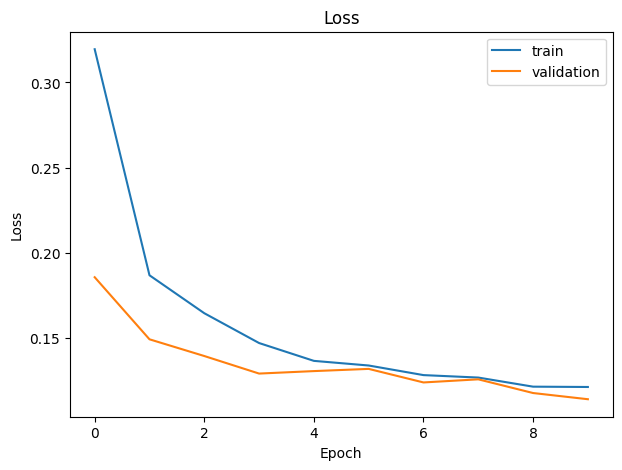

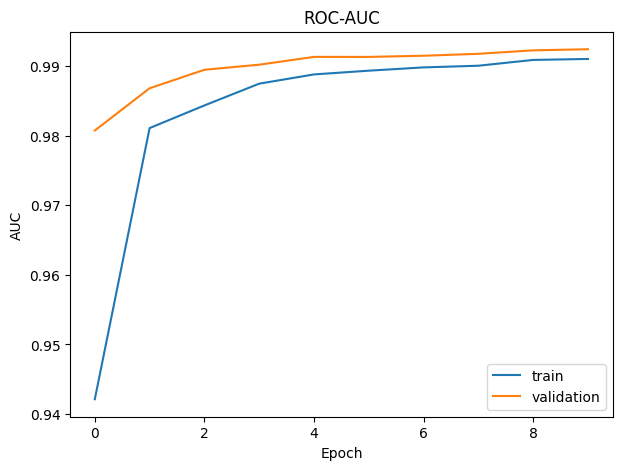

In [13]:
h = history.history

plt.figure(figsize=(7, 5))
plt.plot(h["accuracy"], label="train")
plt.plot(h["val_accuracy"], label="validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(h["loss"], label="train")
plt.plot(h["val_loss"], label="validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(h["auc"], label="train")
plt.plot(h["val_auc"], label="validation")
plt.title("ROC-AUC")
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.legend()
plt.show()


## 13. Load the best model

From this point onward, evaluation uses the saved best model.


In [14]:
best = tf.keras.models.load_model(BEST_MODEL)

print("Model loaded successfully.")


Model loaded successfully.


## 14. Collect validation probabilities

The validation set is used to choose an operating threshold.

**The test set is not used to choose the threshold.**


In [15]:
def collect_predictions(model, dataset):
    y_true = []
    y_prob = []

    for images, labels in dataset:
        probabilities = model.predict(images, verbose=0).ravel()

        y_true.extend(
            labels.numpy().astype(int).ravel().tolist()
        )

        y_prob.extend(
            probabilities.tolist()
        )

    return np.array(y_true), np.array(y_prob)


y_val, p_val = collect_predictions(best, val_ds)

print("Validation true labels:", Counter(y_val))
print("Validation probability range:", float(p_val.min()), "to", float(p_val.max()))

assert len(np.unique(y_val)) == 2, (
    "Validation contains only one class. "
    "Check the split before continuing."
)

val_auc = roc_auc_score(y_val, p_val)
print("Validation ROC-AUC:", f"{val_auc:.4f}")


Validation true labels: Counter({np.int64(1): 1166, np.int64(0): 518})
Validation probability range: 2.542850552345044e-06 to 1.0
Validation ROC-AUC: 0.9924


## 15. Select the anomaly threshold using validation F1

Default threshold is 0.50, but anomaly detection often benefits from a different operating point.

We select the threshold that maximizes **validation F1 for ANOMALY**.

This threshold is then frozen and used once on the test set.


In [16]:
thresholds = np.linspace(0.05, 0.95, 181)

best_threshold = 0.50
best_val_f1 = -1.0

for threshold in thresholds:
    val_pred = (p_val >= threshold).astype(int)

    score = f1_score(
        y_val,
        val_pred,
        pos_label=1,
        zero_division=0
    )

    if score > best_val_f1:
        best_val_f1 = score
        best_threshold = float(threshold)

print("Selected threshold:", best_threshold)
print("Validation anomaly F1:", f"{best_val_f1:.4f}")


Selected threshold: 0.3499999999999999
Validation anomaly F1: 0.9729


## 16. Final TEST evaluation — run this only after the model and threshold are fixed

True labels: Counter({np.int64(1): 1167, np.int64(0): 520})
Predicted labels: Counter({np.int64(1): 1167, np.int64(0): 520})

FINAL TEST ROC-AUC: 0.9942

FINAL CLASSIFICATION REPORT:
              precision    recall  f1-score   support

      NORMAL     0.9423    0.9423    0.9423       520
     ANOMALY     0.9743    0.9743    0.9743      1167

    accuracy                         0.9644      1687
   macro avg     0.9583    0.9583    0.9583      1687
weighted avg     0.9644    0.9644    0.9644      1687

Confusion matrix:
[[ 490   30]
 [  30 1137]]


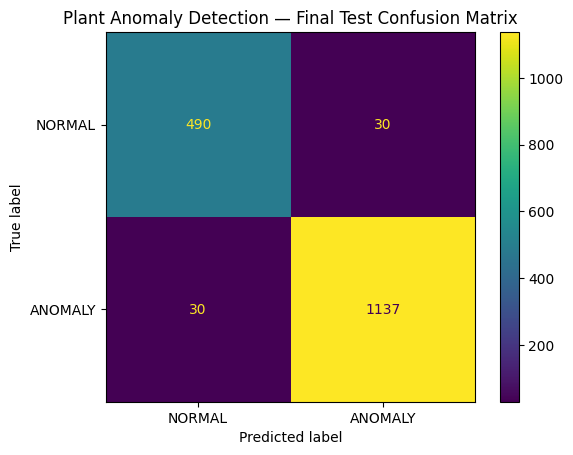

In [17]:
# Collect TEST predictions exactly once.
y_test, p_test = collect_predictions(best, test_ds)

print("True labels:", Counter(y_test))

# This assertion prevents the exact AUC problem from happening silently.
assert len(np.unique(y_test)) == 2, (
    "TEST SET ERROR: only one class is present. "
    "Do not trust the evaluation until the split is fixed."
)

y_pred = (p_test >= best_threshold).astype(int)

print("Predicted labels:", Counter(y_pred))

test_auc = roc_auc_score(y_test, p_test)

print("\nFINAL TEST ROC-AUC:", f"{test_auc:.4f}")

print("\nFINAL CLASSIFICATION REPORT:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["NORMAL", "ANOMALY"],
        digits=4,
        zero_division=0,
    )
)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

print("Confusion matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "ANOMALY"]
).plot()

plt.title("Plant Anomaly Detection — Final Test Confusion Matrix")
plt.show()


## 17. Save final evaluation metrics

In [18]:
report = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["NORMAL", "ANOMALY"],
    digits=4,
    zero_division=0,
    output_dict=True,
)

metrics = {
    "test_auc": float(test_auc),
    "threshold": float(best_threshold),
    "validation_auc": float(val_auc),
    "validation_anomaly_f1": float(best_val_f1),
    "test_accuracy": float(report["accuracy"]),
    "test_normal_precision": float(report["NORMAL"]["precision"]),
    "test_normal_recall": float(report["NORMAL"]["recall"]),
    "test_normal_f1": float(report["NORMAL"]["f1-score"]),
    "test_anomaly_precision": float(report["ANOMALY"]["precision"]),
    "test_anomaly_recall": float(report["ANOMALY"]["recall"]),
    "test_anomaly_f1": float(report["ANOMALY"]["f1-score"]),
    "train_normal": int(train_counts["NORMAL"]),
    "train_anomaly": int(train_counts["ANOMALY"]),
    "val_normal": int(val_counts["NORMAL"]),
    "val_anomaly": int(val_counts["ANOMALY"]),
    "test_normal": int(test_counts["NORMAL"]),
    "test_anomaly": int(test_counts["ANOMALY"]),
}

METRICS_PATH = os.path.join(
    RESULTS_DIR,
    "final_test_metrics_fixed.json"
)

with open(METRICS_PATH, "w") as f:
    json.dump(metrics, f, indent=2)

print(json.dumps(metrics, indent=2))
print("\nSaved:", METRICS_PATH)


{
  "test_auc": 0.9942406565157208,
  "threshold": 0.3499999999999999,
  "validation_auc": 0.9923889216342047,
  "validation_anomaly_f1": 0.9729032258064516,
  "test_accuracy": 0.96443390634262,
  "test_normal_precision": 0.9423076923076923,
  "test_normal_recall": 0.9423076923076923,
  "test_normal_f1": 0.9423076923076923,
  "test_anomaly_precision": 0.974293059125964,
  "test_anomaly_recall": 0.974293059125964,
  "test_anomaly_f1": 0.974293059125964,
  "train_normal": 2419,
  "train_anomaly": 5442,
  "val_normal": 518,
  "val_anomaly": 1166,
  "test_normal": 520,
  "test_anomaly": 1167
}

Saved: /content/drive/MyDrive/TECHCAMP_CIS/results/final_test_metrics_fixed.json


## 18. Optional: precision-recall curve

For anomaly detection, precision/recall can be more informative than accuracy alone.


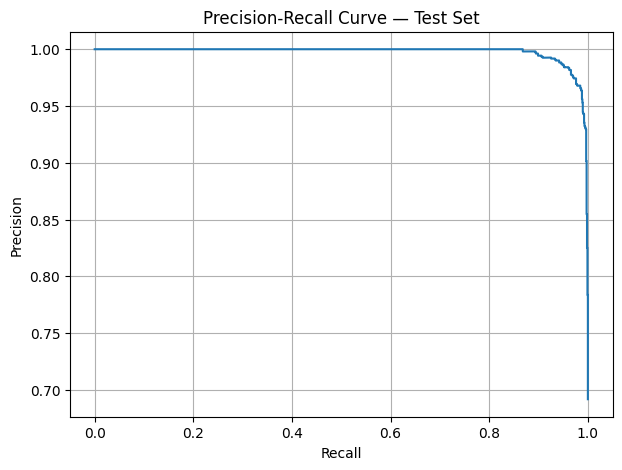

In [19]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_test,
    p_test,
    pos_label=1
)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Test Set")
plt.grid(True)
plt.show()


## 19. Test one image

Remember:

```text
probability >= threshold → ANOMALY
probability < threshold  → NORMAL
```


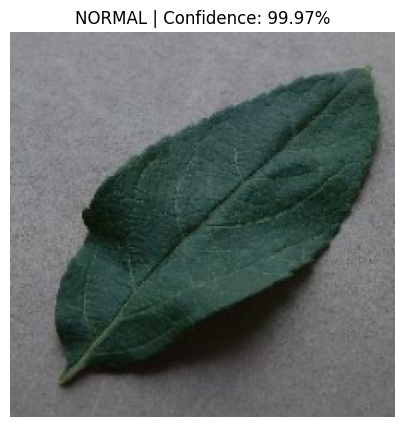

Prediction: NORMAL
Anomaly probability: 0.0003
Confidence: 99.97%


In [20]:
for images, labels in test_ds.take(1):
    image = images[0:1]

    anomaly_probability = float(
        best.predict(image, verbose=0)[0][0]
    )

    if anomaly_probability >= best_threshold:
        status = "ANOMALY"
        confidence = anomaly_probability
    else:
        status = "NORMAL"
        confidence = 1.0 - anomaly_probability

    plt.figure(figsize=(5, 5))
    plt.imshow(images[0].numpy().astype("uint8"))
    plt.axis("off")
    plt.title(
        f"{status} | Confidence: {confidence * 100:.2f}%"
    )
    plt.show()

    print("Prediction:", status)
    print("Anomaly probability:", f"{anomaly_probability:.4f}")
    print("Confidence:", f"{confidence * 100:.2f}%")


## 20. Export TensorFlow Lite for Raspberry Pi

The exported model keeps the exact label mapping used during training:

```text
0 = NORMAL
1 = ANOMALY
```

The saved threshold must also be used by the Raspberry Pi application.


In [21]:
TFLITE_PATH = os.path.join(
    MODEL_DIR,
    "plant_anomaly_mobilenetv2_fixed.tflite"
)

converter = tf.lite.TFLiteConverter.from_keras_model(best)
tflite_model = converter.convert()

with open(TFLITE_PATH, "wb") as f:
    f.write(tflite_model)

LABELS_PATH = os.path.join(MODEL_DIR, "labels.txt")

with open(LABELS_PATH, "w") as f:
    f.write("NORMAL\n")
    f.write("ANOMALY\n")


CONFIG_PATH = os.path.join(MODEL_DIR, "config.json")

config = {
    "model": "plant_anomaly_mobilenetv2_fixed.tflite",
    "input_size": [224, 224],
    "threshold": float(best_threshold),
    "label_0": "NORMAL",
    "label_1": "ANOMALY",
    "output_meaning": "probability_of_anomaly",
    "preprocessing": "MobileNetV2 preprocess_input",
}

with open(CONFIG_PATH, "w") as f:
    json.dump(config, f, indent=2)

print("TFLite:", TFLITE_PATH)
print("Labels:", LABELS_PATH)
print("Config:", CONFIG_PATH)
print("TFLite size MB:", round(os.path.getsize(TFLITE_PATH) / (1024 ** 2), 2))


Saved artifact at '/tmp/tmply5w85cp'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  133213343203792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133213343211280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133213343210704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133213343211472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133213343213584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133213343211664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133213343206480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133213343204368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133213343212816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133213343213200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1332133432126

## 21. Final consistency checks

These checks make sure the notebook's training/evaluation/deployment label mapping is consistent.


In [22]:
assert CLASS_NAMES == ["NORMAL", "ANOMALY"]
assert config["label_0"] == "NORMAL"
assert config["label_1"] == "ANOMALY"
assert config["output_meaning"] == "probability_of_anomaly"
assert 0.0 < config["threshold"] < 1.0
assert len(np.unique(y_test)) == 2

print("All consistency checks passed.")
print("0 = NORMAL")
print("1 = ANOMALY")
print("Sigmoid output = ANOMALY probability")
print("Deployment threshold =", config["threshold"])


All consistency checks passed.
0 = NORMAL
1 = ANOMALY
Sigmoid output = ANOMALY probability
Deployment threshold = 0.3499999999999999


# 22. Raspberry Pi deployment architecture

After export, Google Colab is **not** part of the live robot loop.

```text
Google Colab
    │
    │ plant_anomaly_mobilenetv2_fixed.tflite
    │ labels.txt
    │ config.json
    ▼
Raspberry Pi
    │
    ├── Camera
    │      ↓
    ├── Resize 224×224
    │      ↓
    ├── MobileNetV2 preprocessing
    │      ↓
    ├── TFLite inference
    │      ↓
    ├── anomaly probability
    │      ↓
    ├── threshold decision
    │      ├── NORMAL
    │      └── ANOMALY
    │
    └── Robot control + HDMI display
```

Transfer these files to the Raspberry Pi:

```text
plant_anomaly_mobilenetv2_fixed.tflite
labels.txt
config.json
```

The Raspberry Pi should read the threshold from `config.json` rather than hard-coding a different threshold.


# 23. What changed from the broken notebook?

### Old behavior

```text
holdout_ds (shuffle=False)
        ↓
take(first batches) → validation
skip(first batches) → test
```

Because the images were ordered by class, the test set could become:

```text
NORMAL = 1673
ANOMALY = 0
```

Then:

```text
ROC-AUC = nan
ANOMALY support = 0
```

### New behavior

```text
NORMAL files ──┬── 70% train
               ├── 15% validation
               └── 15% test

ANOMALY files ─┬── 70% train
               ├── 15% validation
               └── 15% test
```

So every split contains both classes.

This means the final test metrics are actually measuring the binary classification problem.


# 24. Final checklist

### Training
- [ ] Dataset downloaded to Colab
- [ ] NORMAL/ANOMALY mapping verified
- [ ] Train/validation/test distributions verified
- [ ] MobileNetV2 trained
- [ ] Best model saved

### Evaluation
- [ ] Validation AUC calculated
- [ ] Threshold selected on validation only
- [ ] Test contains both classes
- [ ] Test ROC-AUC calculated
- [ ] Precision / recall / F1 calculated
- [ ] Confusion matrix generated

### Deployment
- [ ] `.keras` model saved
- [ ] `.tflite` model saved
- [ ] `labels.txt` saved
- [ ] `config.json` saved
- [ ] Threshold in Raspberry Pi matches `config.json`

**Important:** Do not judge the new model by the old `86.43%` result. That old result came from a test set containing only NORMAL samples and therefore was not a valid anomaly-detection evaluation.
